# 01 · California Housing Data Cleaning

**Input:** `../data/raw/california_housing_raw.csv` (មិនកែប្រែជាដាច់ខាត)
**Output:** `../data/processed/california_housing_clean.csv`

**ច្បាប់សំខាន់នៃ notebook នេះ:** យើងធ្វើតែជំហាន cleaning ដែល **មិនរៀនពី data** ទេ ដូចជា fix data types,
drop columns ដែល leak ឬស្ទួន, ដក rows ដែលមាន label ខុស, ពិនិត្យ missing values, duplicates និង outliers។

ជំហានដែល **រៀន statistics ពី data** (ឧ. scaling, fill ដោយ mean/median)
ត្រូវធ្វើនៅក្នុង algorithm notebook **បន្ទាប់ពី Train/Test Split** ហើយ fit លើ training set តែប៉ុណ្ណោះ។
Feature Engineering ក៏មិនធ្វើនៅទីនេះដែរ (មើល `src/features.py` ក្នុង notebook 09)។

## Step 1 · Load the raw data and take a first look

Import libraries ហើយកំណត់ឲ្យ pandas បង្ហាញ columns ទាំងអស់។

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", None)

RAW_PATH = "../data/raw/california_housing_raw.csv"
CLEAN_PATH = "../data/processed/california_housing_clean.csv"

អាន raw CSV ចូល DataFrame ហើយមើល shape `(rows, columns)`។ យើងរក្សាទុក `raw` ដើម្បីប្រៀបធៀបនៅចុងក្រោយ ហើយធ្វើការលើ `df` ដែលជា copy។

In [2]:
raw = pd.read_csv(RAW_PATH)
df = raw.copy()
df.shape

(20640, 9)

មើល 5 rows ដំបូង ដើម្បីឃើញរូបរាង data ពិត។

In [3]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


**Row នីមួយៗមិនមែនជាផ្ទះមួយខ្នងទេ។** វាជា **block group** មួយពីជំរឿនរដ្ឋ California ឆ្នាំ 1990 គឺជាសង្កាត់ដែលមានមនុស្សប្រហែល 600–3,000 នាក់។

| Column | អត្ថន័យ (សម្រាប់ block group នីមួយៗ) |
|---|---|
| `MedInc` | ចំណូលមេដ្យាន គិតជាឯកតា $10,000 |
| `HouseAge` | អាយុមេដ្យានរបស់ផ្ទះ គិតជាឆ្នាំ |
| `AveRooms` | ចំនួនបន្ទប់ជាមធ្យមក្នុងមួយគ្រួសារ |
| `AveBedrms` | ចំនួនបន្ទប់គេងជាមធ្យមក្នុងមួយគ្រួសារ |
| `Population` | ចំនួនប្រជាជន |
| `AveOccup` | ចំនួនមនុស្សជាមធ្យមក្នុងមួយគ្រួសារ |
| `Latitude`, `Longitude` | ទីតាំង (ជើង–ត្បូង, កើត–លិច) |
| `MedHouseVal` | **target**: តម្លៃផ្ទះមេដ្យាន គិតជាឯកតា $100,000 (`2.5` = $250,000) |

ពិនិត្យ data type ដែល pandas បានទាយសម្រាប់ column នីមួយៗ។

In [4]:
df.dtypes

MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

## Step 2 · Missing values overview

រាប់ missing values (`NaN`) ក្នុង column នីមួយៗ ជាចំនួន និងជាភាគរយ ហើយតម្រៀបពីច្រើនទៅតិច។

In [5]:
missing = pd.DataFrame({
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(1),
}).sort_values("n_missing", ascending=False)
missing

,n_missing,pct_missing
MedInc,0,0.0
HouseAge,0,0.0
AveRooms,0,0.0
AveBedrms,0,0.0
Population,0,0.0
AveOccup,0,0.0
Latitude,0,0.0
Longitude,0,0.0
MedHouseVal,0,0.0


**អានលទ្ធផល:** មិនមាន missing values សោះ។ ទាំង 9 columns ពេញលេញ 20,640 rows។ ដូច្នេះគ្មានអ្វីត្រូវ fill ឬ drop ទេ
(ផ្ទុយពី Titanic ដែលត្រូវសម្រេចយុទ្ធសាស្ត្រសម្រាប់ `deck`, `age`, `embarked`)។ នេះមានន័យថា algorithm notebooks មិនត្រូវការ `SimpleImputer` ទេ។

## Step 3 · Leakage check

**Data leakage** គឺពេល feature មួយផ្ទុកព័ត៌មានអំពីចម្លើយ (target) ដែលយើងមិនអាចដឹងនៅពេលទាយពិតប្រាកដ។
ក្នុង Titanic, `alive` គឺ `survived` ដែលសរសេរជាអក្សរ។ ត្រង់នេះយើងត្រូវពិនិត្យថា គ្មាន feature ណាជាច្បាប់ចម្លងរបស់ `MedHouseVal`។
វិធីរហ័ស: មើល correlation នៃ feature នីមួយៗជាមួយ target។ ប្រសិនបើមាន feature ណាមួយជិត ±1 នោះគួរឲ្យសង្ស័យ។

In [6]:
df.drop(columns="MedHouseVal").corrwith(df["MedHouseVal"]).round(3).sort_values()

Latitude     -0.144
AveBedrms    -0.047
Longitude    -0.046
Population   -0.025
AveOccup     -0.024
HouseAge      0.106
AveRooms      0.152
MedInc        0.688
dtype: float64

**អានលទ្ធផល:** គ្មាន feature ណាជិត ±1 ទេ។ `MedInc` មាន correlation ខ្លាំងបំផុត (+0.69) ហើយនោះជាទំនាក់ទំនងពិតប្រាកដ
(ចំណូលខ្ពស់ → ផ្ទះថ្លៃ) មិនមែន leakage ទេ។ គ្មាន column ណាមួយជា target ដែលសរសេរជាទម្រង់ផ្សេងឡើយ ហើយ features ទាំងអស់អាចដឹងបាន **មុន** ពេលយើងដឹងតម្លៃផ្ទះ
(ជំរឿនវាស់ចំណូល អាយុផ្ទះ និងចំនួនប្រជាជន)។ ដូច្នេះមិនចាំបាច់ drop column ណាទេ។

⚠️ `Latitude` មាន correlation ត្រឹមតែ −0.14 ប៉ុន្តែនោះមិនមានន័យថាទីតាំងមិនសំខាន់ទេ។ Correlation វាស់តែទំនាក់ទំនង **ត្រង់** ជាមួយ column មួយក្នុងមួយពេល។
តម្លៃអាស្រ័យលើ `Latitude` និង `Longitude` **រួមគ្នា** (ជិតមាត់សមុទ្រ និងទីក្រុងធំ) ដែលយើងនឹងឃើញក្នុង notebook 04 (Decision Tree)។

## Step 4 · The capped target (`MedHouseVal`)

ជំរឿនមិនបានកត់ត្រាតម្លៃផ្ទះដែលលើសពី $500,000 ទេ។ គ្រប់សង្កាត់ដែលលើសពីនោះ ត្រូវបានកត់ជា `5.00001`។
Histogram នេះបង្ហាញសសរ (bar) ខ្ពស់ខុសធម្មតានៅខាងស្តាំបំផុត។

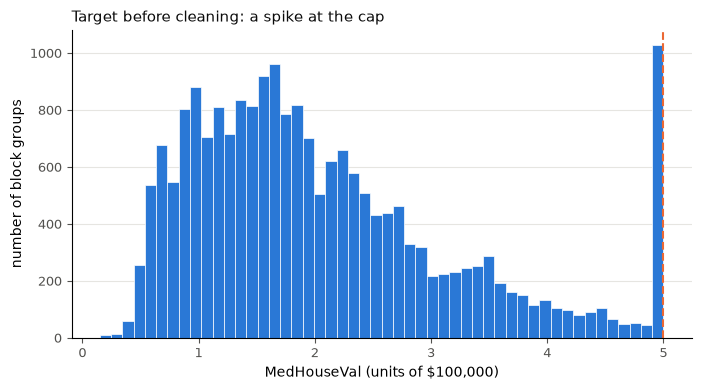

In [7]:
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e1"

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["MedHouseVal"], bins=50, color=BLUE, edgecolor="white", linewidth=0.5)
ax.axvline(5.0, color=ORANGE, linewidth=1.5, linestyle="--")
ax.set_xlabel("MedHouseVal (units of $100,000)"); ax.set_ylabel("number of block groups")
ax.set_title("Target before cleaning: a spike at the cap", loc="left", fontsize=11, color=INK)
ax.grid(axis="y", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.tick_params(colors=MUTED, labelsize=9)
plt.show()

រាប់ rows ដែលជាប់ cap។ ហើយពិនិត្យ columns ផ្សេងទៀតដែលមាន cap ស្រដៀងគ្នា (`HouseAge`, `MedInc`)។

In [8]:
n_capped = int((df["MedHouseVal"] >= 5.0).sum())
{
    "max MedHouseVal": float(df["MedHouseVal"].max()),
    "rows at the cap (>= 5.0)": n_capped,
    "pct of all rows": round(n_capped / len(df) * 100, 1),
    "HouseAge == 52 (max)": int((df["HouseAge"] == df["HouseAge"].max()).sum()),
    "MedInc >= 15 (max)": int((df["MedInc"] >= 15).sum()),
}

{'max MedHouseVal': 5.00001,
 'rows at the cap (>= 5.0)': 992,
 'pct of all rows': 4.8,
 'HouseAge == 52 (max)': 1273,
 'MedInc >= 15 (max)': 51}

**អានលទ្ធផល:** `MedHouseVal` ជាប់ cap នៅ `5.00001` ចំនួន **992 rows (4.8%)**។ តម្លៃពិតរបស់សង្កាត់ទាំងនេះលើសពី $500,000 ប៉ុន្តែមិនត្រូវបានកត់ត្រា។

**ការសម្រេចចិត្ត: ដក 992 rows នេះចេញ។**
- សម្រាប់ rows ទាំងនេះ label **ខុស** មិនមែនគ្រាន់តែធំទេ។ សង្កាត់ដែលមានតម្លៃ $900,000 ត្រូវបានកត់ជា $500,001។
  បើទុកវា model រៀនថាតំបន់អ្នកមានមាត់សមុទ្រមានតម្លៃ $500k គត់ ហើយយើងក៏ដាក់ពិន្ទុ model ដោយប្រៀបធៀបនឹងចម្លើយខុសដែរ។
- ច្បាប់នេះ **មិនរៀនពី data** ទេ ("តម្លៃ ≥ 5.0 គឺ cap") ដូច្នេះមិនមាន leakage ទេ។
- **តម្លៃដែលយើងត្រូវបង់:** model នឹងត្រឹមត្រូវតែសម្រាប់សង្កាត់ដែលមានតម្លៃក្រោម $500,000 ប៉ុណ្ណោះ។ យើងសរសេរដែនកំណត់នេះក្នុង README។
- Clip (កាត់ឲ្យស្មើ 5.0) មិនជួយទេ ព្រោះតម្លៃត្រូវបាន clip រួចហើយ ហើយនោះហើយជាបញ្ហា។

`HouseAge` ជាប់ cap នៅ 52 (1,273 rows) ហើយ `MedInc` ជាប់ cap នៅ 15.0001 (51 rows)។ ទាំងពីរជា cap ដូចគ្នា ប៉ុន្តែ **ស្រាល** ហើយ label ជា feature មិនមែន target
ដូច្នេះ model នៅតែរៀនបាន (ឧ. "ផ្ទះចាស់ ≥ 52 ឆ្នាំ")។ យើង **រក្សា** ពួកវា។

In [9]:
df = df[df["MedHouseVal"] < 5.0].copy()
df.shape

(19648, 9)

## Step 5 · Duplicated rows

`df.duplicated()` រាប់ rows ដែលដូចគ្នាទាំងស្រុងនឹង row មុនៗ។ ក្នុង Titanic duplicates ច្រើនជាមនុស្សពិតខុសគ្នា ព្រោះគ្មាន `name`។
ត្រង់នេះ features ជាលេខទសភាគបន្ត ដូច្នេះប្រសិនបើ 9 columns ដូចគ្នាទាំងអស់ វាគួរឲ្យសង្ស័យថាជា row ដដែលដែលចុះឈ្មោះពីរដង។

In [10]:
int(df.duplicated().sum())

0

ពិនិត្យបន្ថែម: block groups ដែលចែក coordinates (`Latitude`, `Longitude`) ដូចគ្នា។

In [11]:
int(df.duplicated(subset=["Latitude", "Longitude"], keep=False).sum())

11747

**អានលទ្ធផល:** **គ្មាន exact duplicates សោះ** (0)។ ជាមួយ features លេខទសភាគ 9 columns ការដូចគ្នាទាំងស្រុងពិបាកកើតដោយចៃដន្យ ដូច្នេះគ្មានអ្វីត្រូវសម្រេចទេ
(ផ្ទុយពី Titanic ដែលមាន 107 duplicates ហើយត្រូវស៊ើបអង្កេត)។ នេះមានន័យថា notebook 03–07 មិនត្រូវការផ្នែក "Duplicates across train and test" ទេ។

Coordinates ស្ទួនគ្នា 11,747 rows ប៉ុន្តែនោះជារឿងធម្មតា: `Latitude` និង `Longitude` ត្រូវបានបង្គត់ត្រឹម 0.01° (≈ 1 km) ដូច្នេះ block groups ជាច្រើនក្នុងទីក្រុងតែមួយ
ចែកចំណុចដូចគ្នា។ ពួកវាជាសង្កាត់ខុសគ្នា (ចំណូល, ចំនួនប្រជាជន, តម្លៃខុសគ្នា) ដូច្នេះ **រក្សាទាំងអស់**។

## Step 6 · Data types

Titanic មាន categorical columns (`sex`, `embarked`, `deck`) ដែលត្រូវប្តូរទៅ `category`។ ត្រង់នេះពិនិត្យថា columns ទាំងអស់ជាលេខឬអត់។

In [12]:
{
    "dtypes": df.dtypes.astype(str).value_counts().to_dict(),
    "non-numeric columns": df.select_dtypes(exclude="number").columns.tolist(),
}

{'dtypes': {'float64': 9}, 'non-numeric columns': []}

**អានលទ្ធផល:** Columns ទាំង 9 ជា `float64` ហើយមិនមាន column អក្សរ (categorical) ទេ។ ដូច្នេះ:
- មិនចាំបាច់ប្តូរ dtype ទេ។
- មិនត្រូវការ `OneHotEncoder` ក្នុង algorithm notebooks។
- Preprocessing ទាំងមូលសម្រាប់ notebooks 02–09 គឺគ្រាន់តែ `StandardScaler` (សម្រាប់ models ដែលត្រូវការ)។

## Step 7 · Outliers

**Outlier** គឺជាតម្លៃដែលឆ្ងាយពីតម្លៃភាគច្រើន។ មានពីរប្រភេទ:
1. **Error ឬ "មិនមែនជាផ្ទះធម្មតា"**: តម្លៃដែលមិនតំណាងឲ្យ data ដែលយើងចង់ទាយ → ត្រូវដក។
2. **Real extreme value**: តម្លៃកម្រ ប៉ុន្តែពិត (ឧ. សង្កាត់ដែលមានប្រជាជនច្រើនខ្លាំង) → ត្រូវ **រក្សា**។

ចាប់ផ្តើមជាមួយ `describe()`។ ប្រៀបធៀប `max` ជាមួយ `75%` ដើម្បីរកតម្លៃខុសធម្មតា។

In [13]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
MedInc,19648.0,3.68,1.57,0.50,2.53,3.45,4.58,15.00
HouseAge,19648.0,28.37,12.50,1.00,18.00,28.00,37.00,52.00
AveRooms,19648.0,5.36,2.29,0.85,4.42,5.19,5.97,132.53
AveBedrms,19648.0,1.10,0.45,0.33,1.01,1.05,1.10,34.07
Population,19648.0,1441.37,1144.08,3.00,796.00,1179.00,1746.25,35682.00
AveOccup,19648.0,3.10,10.64,0.69,2.45,2.84,3.31,1243.33
Latitude,19648.0,35.65,2.15,32.54,33.93,34.27,37.73,41.95
Longitude,19648.0,-119.56,2.01,-124.35,-121.76,-118.50,-117.99,-114.31
MedHouseVal,19648.0,1.92,0.97,0.15,1.16,1.74,2.48,4.99


Boxplot បង្ហាញ median (បន្ទាត់កណ្តាល), IQR (ប្រអប់) និង outliers (ចំណុចក្រៅ whiskers)។
ត្រូវប្រើ **log scale** ព្រោះតម្លៃធំបំផុតធំជាង median រាប់រយដង បើមិនដូច្នោះទេ ប្រអប់នឹងតូចរហូតមើលមិនឃើញ។

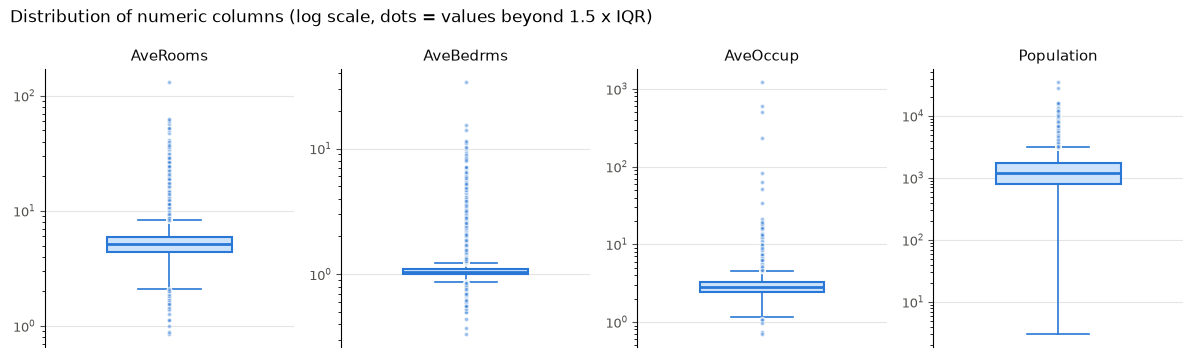

In [14]:
cols = ["AveRooms", "AveBedrms", "AveOccup", "Population"]
fig, axes = plt.subplots(1, 4, figsize=(12, 3.6))
for ax, col in zip(axes, cols):
    ax.boxplot(
        df[col], widths=0.5, patch_artist=True,
        boxprops={"facecolor": "#cde2fb", "edgecolor": BLUE, "linewidth": 1.5},
        medianprops={"color": BLUE, "linewidth": 2},
        whiskerprops={"color": BLUE, "linewidth": 1.2},
        capprops={"color": BLUE, "linewidth": 1.2},
        flierprops={"marker": "o", "markersize": 3, "markerfacecolor": BLUE,
                    "markeredgecolor": "white", "alpha": 0.5},
    )
    ax.set_yscale("log")
    ax.set_title(col, fontsize=11, color=INK)
    ax.set_xticks([])
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right", "bottom"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(axis="y", colors=MUTED, labelsize=9)
fig.suptitle("Distribution of numeric columns (log scale, dots = values beyond 1.5 x IQR)", fontsize=12, x=0.01, ha="left")
fig.tight_layout()
plt.show()

ពិនិត្យ extreme values ដោយផ្ទាល់។ **AveRooms ខ្ពស់បំផុត:**

In [15]:
df.sort_values("AveRooms", ascending=False).head(6)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
1979,4.6250,34.0,132.533333,34.066667,36.0,2.400000,38.80,-120.08,1.625
12447,1.6154,17.0,62.422222,14.111111,83.0,1.844444,33.97,-114.49,0.875
1913,4.0714,19.0,61.812500,11.000000,112.0,2.333333,39.01,-120.06,4.375
11862,2.6250,25.0,59.875000,15.312500,28.0,1.750000,40.27,-121.25,0.675
1912,4.9750,16.0,56.269231,10.153846,54.0,2.076923,39.01,-120.16,2.063
9676,3.2431,14.0,52.848214,11.410714,265.0,2.366071,37.64,-119.02,2.214


**AveOccup ខ្ពស់បំផុត:**

In [16]:
df.sort_values("AveOccup", ascending=False).head(6)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
19006,10.2264,45.0,3.166667,0.833333,7460.0,1243.333333,38.32,-121.98,1.375
3364,5.5179,36.0,5.142857,1.142857,4198.0,599.714286,40.41,-120.51,0.675
16669,4.2639,46.0,9.076923,1.307692,6532.0,502.461538,35.32,-120.70,3.500
13034,6.1359,52.0,8.275862,1.517241,6675.0,230.172414,38.69,-121.15,2.250
9172,4.2391,5.0,5.123810,0.933333,8733.0,83.171429,34.47,-118.59,1.546
12104,1.6250,8.0,7.600000,0.950000,1275.0,63.750000,33.97,-117.33,1.625


សាកល្បងកំណត់ច្បាប់ថេរ (fixed rule): "គ្រួសារធម្មតាមិនមានជាមធ្យមលើសពី **15 បន្ទប់** ឬ **6 នាក់**" ហើយរាប់ថាមាន rows ប៉ុន្មានខុសច្បាប់នេះ។
ពិនិត្យផងដែរថាតើតម្លៃទាំងនោះមានអ្វីខុសគ្នាពី block groups ផ្សេងទៀត។

In [17]:
MAX_ROOMS, MAX_OCCUP = 15, 6
not_a_home = (df["AveRooms"] > MAX_ROOMS) | (df["AveOccup"] > MAX_OCCUP)
pd.DataFrame({
    "rows": [int(not_a_home.sum()), int((~not_a_home).sum())],
    "median Population": [df.loc[not_a_home, "Population"].median(), df.loc[~not_a_home, "Population"].median()],
    "median AveRooms": [df.loc[not_a_home, "AveRooms"].median(), df.loc[~not_a_home, "AveRooms"].median()],
    "median AveOccup": [df.loc[not_a_home, "AveOccup"].median(), df.loc[~not_a_home, "AveOccup"].median()],
    "median MedHouseVal": [df.loc[not_a_home, "MedHouseVal"].median(), df.loc[~not_a_home, "MedHouseVal"].median()],
}, index=["beyond the rule", "normal block groups"]).round(2)

,rows,median Population,median AveRooms,median AveOccup,median MedHouseVal
beyond the rule,215,571.0,11.38,6.02,1.53
normal block groups,19433,1183.0,5.18,2.84,1.74


ពិនិត្យតម្លៃដែល **មិនអាចកើតមាន** (errors) ផងដែរ: បន្ទប់គេងច្រើនជាងបន្ទប់សរុប, និង coordinates ក្រៅរដ្ឋ California។

In [18]:
{
    "AveBedrms > AveRooms": int((df["AveBedrms"] > df["AveRooms"]).sum()),
    "Latitude outside 32.5-42.0": int((~df["Latitude"].between(32.5, 42.0)).sum()),
    "Longitude outside -124.5 to -114.1": int((~df["Longitude"].between(-124.5, -114.1)).sum()),
    "Population < 1 or AveOccup <= 0": int(((df["Population"] < 1) | (df["AveOccup"] <= 0)).sum()),
}

{'AveBedrms > AveRooms': 0,
 'Latitude outside 32.5-42.0': 0,
 'Longitude outside -124.5 to -114.1': 0,
 'Population < 1 or AveOccup <= 0': 0}

**ការសម្រេចចិត្ត: ដក 215 rows ដែលលើសច្បាប់ (`AveRooms > 15` ឬ `AveOccup > 6`)។ រក្សា outliers ផ្សេងទៀតទាំងអស់។**

**អ្វីដែលតម្លៃទាំងនេះបង្ហាញ:**
- `AveRooms` ខ្ពស់បំផុតគឺ 132.5 បន្ទប់ក្នុងមួយគ្រួសារ ដោយមានប្រជាជនត្រឹមតែ 36 នាក់។ `AveOccup` ខ្ពស់បំផុតគឺ 1,243 នាក់ក្នុងមួយគ្រួសារ (ប្រជាជន 7,460)។
  ទាំងនេះមិនអាចជាផ្ទះធម្មតាបានទេ។ ទំនងជាកន្លែងដូចជារមណីយដ្ឋានវិស្សមកាល (បន្ទប់ច្រើន ស្ទើរតែគ្មានគ្រួសាររស់នៅអចិន្ត្រៃយ៍)
  ឬពន្ធនាគារ/អន្តេវាសិកដ្ឋាន (មនុស្សច្រើន តែរាប់ជាគ្រួសារតិច)។
- ក្រុម 215 rows នេះខុសពីធម្មតាច្បាស់: `Population` median 571 (ធម្មតា 1,183), `AveRooms` median 11.4 (ធម្មតា 5.2), `AveOccup` median 6.0 (ធម្មតា 2.8)។
  ពួកវាជា **ប្រភេទកន្លែងផ្សេង** ដូច្នេះមិនជួយទាយតម្លៃផ្ទះធម្មតាទេ។
- ពួកវាប៉ះពាល់ដល់ linear models ខ្លាំង: row តែមួយដែលមាន `AveOccup = 1243` អាចទាញបន្ទាត់ទាំងមូលឲ្យវៀច។

**ហេតុអ្វីជាច្បាប់ថេរ មិនមែន percentile?** "15 បន្ទប់ / 6 នាក់" ជាច្បាប់ដែលអាចពន្យល់បាន ហើយអនុវត្តលើ row ណាមួយបានដោយមិនត្រូវមើល rows ផ្សេង។
បើប្រើ percentile (ឧ. 99.5%) យើងកំពុង **រៀនពី data** ហើយ threshold នឹងប្រែតាមសំណុំទិន្នន័យ។

**អ្វីដែលយើងរក្សា:**
- ពិនិត្យ errors: គ្មាន row ណាដែល `AveBedrms > AveRooms` ទេ, គ្មាន coordinates ក្រៅរដ្ឋ California, គ្មាន `Population` ឬ `AveOccup` ដែលមិនអាចកើតមាន។ ដូច្នេះគ្មាន **error** ពិតប្រាកដ។
- `Population` ខ្ពស់បំផុត (35,682) ជា block group ធំពិតៗ ដែលមាន `AveOccup` ធម្មតា។ នេះជា real extreme ដូច្នេះរក្សា។
- សម្រាប់ `AveBedrms` ធំៗ: ពួកវាស្ទើរតែទាំងអស់ត្រូវបានដកចេញរួចតាមរយៈ `AveRooms > 15` ពីព្រោះវាជាសង្កាត់ប្រភេទដូចគ្នា។

In [19]:
n_not_a_home = int(not_a_home.sum())
df = df[~not_a_home].reset_index(drop=True)
df.shape

(19433, 9)

## Step 8 · Sanity checks

`assert` បញ្ឈប់ notebook ភ្លាមៗជាមួយ error បើលក្ខខណ្ឌណាមួយមិនពិត។ វាការពារមិនឲ្យយើង save data ខុសដោយមិនដឹងខ្លួន។

In [20]:
EXPECTED_COLUMNS = ["MedInc", "HouseAge", "AveRooms", "AveBedrms", "Population",
                    "AveOccup", "Latitude", "Longitude", "MedHouseVal"]

assert df.columns.tolist() == EXPECTED_COLUMNS, f"unexpected columns: {df.columns.tolist()}"
assert df.isna().sum().sum() == 0, "there are still missing values"
assert df["MedHouseVal"].max() < 5.0, "capped target rows are still present"
assert (df["AveRooms"] <= MAX_ROOMS).all() and (df["AveOccup"] <= MAX_OCCUP).all(), "not-a-home rows are still present"
assert len(df) == len(raw) - n_capped - n_not_a_home, "row count does not match the removed rows"
assert not df.duplicated().any(), "duplicated rows found"
assert (df.dtypes == "float64").all(), "all columns should be float64"
"all checks passed"

'all checks passed'

## Step 9 · Save and verify

Save ទៅ `data/processed/` (**មិនដែល** save ជាន់ `data/raw/`)។ `index=False` ការពារមិនឲ្យ pandas បន្ថែម column index ក្នុង file។

In [21]:
df.to_csv(CLEAN_PATH, index=False)
CLEAN_PATH

'../data/processed/california_housing_clean.csv'

Reload file ដែលទើប save ដើម្បីបញ្ជាក់ថាវាត្រឹមត្រូវ។ ពិនិត្យ shape, missing values និង dtypes។

In [22]:
clean = pd.read_csv(CLEAN_PATH)
clean.shape

(19433, 9)

In [23]:
int(clean.isna().sum().sum()), clean.dtypes.astype(str).unique().tolist()

(0, ['float64'])

**ចំណាំ:** ផ្ទុយពី Titanic, CSV នេះមិនមាន `category` columns ទេ ដូច្នេះ dtype មិនបាត់បង់ពេល reload (គ្រប់ columns នៅតែជា `float64`)។
នៅទីនេះមិនចាំបាច់ប្រើ `dtype=` ក្នុង `pd.read_csv` ទេ។ ផ្ទៀងផ្ទាត់ថា data ដែល reload ដូចគ្នាបេះបិទនឹង `df`:

In [24]:
pd.testing.assert_frame_equal(clean, df)
"data identical after reload"

'data identical after reload'

ប្រៀបធៀប before vs after។

In [25]:
{
    "raw_shape": raw.shape,
    "clean_shape": clean.shape,
    "removed_capped_target": n_capped,
    "removed_not_a_home": n_not_a_home,
    "pct_rows_kept": round(len(clean) / len(raw) * 100, 1),
    "dropped_columns": [c for c in raw.columns if c not in clean.columns],
    "added_columns": [c for c in clean.columns if c not in raw.columns],
}

{'raw_shape': (20640, 9),
 'clean_shape': (19433, 9),
 'removed_capped_target': 992,
 'removed_not_a_home': 215,
 'pct_rows_kept': 94.2,
 'dropped_columns': [],
 'added_columns': []}

## Cleaning summary

| # | Decision | Reason | Learns from data? |
|---|----------|--------|-------------------|
| 1 | No missing values to handle | 0 NaN ក្នុង 9 columns ទាំងអស់ | No |
| 2 | No leaky column to drop | Features ទាំងអស់ដឹងបានមុនតម្លៃ។ ខ្ពស់បំផុត `MedInc` +0.69 ជាទំនាក់ទំនងពិត | No |
| 3 | Remove 992 rows with `MedHouseVal >= 5.0` | Label ជាប់ cap ($500,001) → ខុស។ Model ត្រឹមត្រូវតែក្រោម $500k | No (fixed rule) |
| 4 | Keep `HouseAge == 52` (1,273) and `MedInc >= 15` (51) | cap ស្រាលលើ feature។ Model នៅតែរៀនបាន | No |
| 5 | Keep all rows, no duplicates | 0 exact duplicates។ Coordinates ស្ទួន = សង្កាត់ខុសគ្នា (បង្គត់ 0.01°) | No |
| 6 | No dtype change | 9 columns ជា `float64`, គ្មាន categorical | No |
| 7 | Remove 215 rows with `AveRooms > 15` or `AveOccup > 6` | មិនមែនជាផ្ទះធម្មតា (រមណីយដ្ឋាន, ពន្ធនាគារ, អន្តេវាសិកដ្ឋាន)។ ច្បាប់ថេរ មិនមែន percentile | No (fixed rule) |
| 8 | Keep all other outliers | គ្មាន error ។ `Population` ធំ ជាសង្កាត់ធំពិត | No |
| 9 | No feature engineering here | features ថ្មីៗ (ឧ. `bedrooms_ratio`) ត្រូវបង្កើតក្នុង `src/features.py` (notebook 09) ហើយវាស់ថាជួយឬអត់ | No |

**Result:** 19,433 rows × 9 columns (94.2% នៃ 20,640), saved to `data/processed/california_housing_clean.csv`។
**NaNs left on purpose:** គ្មាន។ **Scaling** ត្រូវធ្វើក្នុង algorithm notebook ក្រោយ split ដោយ fit លើ training set តែប៉ុណ្ណោះ។

In [26]:
clean = pd.read_csv("../data/processed/california_housing_clean.csv")
clean.groupby(pd.qcut(clean["MedInc"], 4, labels=["Q1 (lowest income)", "Q2", "Q3", "Q4 (highest income)"]),
              observed=True)["MedHouseVal"].agg(["size", "mean"]).round(2)

,size,mean
MedInc,,
Q1 (lowest income),4859,1.20
Q2,4858,1.66
Q3,4858,2.04
Q4 (highest income),4858,2.80


**Answer:** សង្កាត់ដែលមានចំណូលខ្ពស់បំផុត (Q4) មានតម្លៃផ្ទះមធ្យម ≈ 2.80 ($280,000) ខ្ពស់ជាង Q1 (≈ 1.20 = $120,000) ប្រហែល **2.3 ដង**។
តម្លៃកើនឡើងជាលំដាប់ពី Q1 ដល់ Q4 (1.20 → 1.66 → 2.04 → 2.80) ហើយគម្លាតធំបំផុតនៅ Q3 → Q4។ នេះត្រូវនឹង correlation +0.69 របស់ `MedInc` ហើយបង្ហាញថា `MedInc` ជា feature សំខាន់បំផុតសម្រាប់ model ជាបន្តបន្ទាប់។